In [1]:
import sys
from pathlib import Path

# Allow `from src...` whether the kernel starts in the repo root or notebooks/.
root = Path.cwd()
while not (root / 'src').exists() and root != root.parent:
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))


# 01 — Exploratory Data Analysis

Calls the versioned `src/` pipeline rather than duplicating logic. Ends with the hypotheses the modelling stage tests.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from src.utils.config import get_project_root

root = get_project_root()
df = pd.read_parquet(root / 'data/interim/cleaned_transactions.parquet')
df.shape

(794440, 10)

In [3]:
summary = df.groupby('customer_id').agg(
    last_purchase=('invoice_date', 'max'),
    frequency=('invoice', 'nunique'),
    monetary=('line_total', 'sum'),
)
summary['recency_days'] = (df['invoice_date'].max() - summary['last_purchase']).dt.days
summary[['recency_days', 'frequency', 'monetary']].describe()

,recency_days,frequency,monetary
count,5876.000000,5876.000000,5876.000000
mean,198.585773,7.473111,2783.550163
std,209.399643,15.386409,13820.598853
min,0.000000,1.000000,-1343.240000
25%,24.000000,2.000000,328.700000
50%,93.000000,4.000000,835.340000
75%,377.250000,8.000000,2164.260000
max,738.000000,468.000000,578408.640000


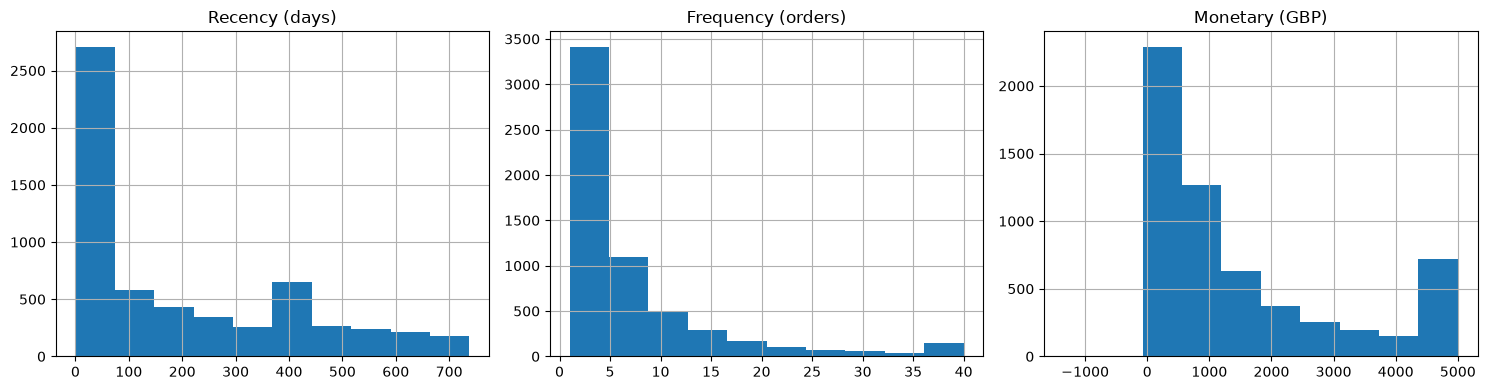

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
summary['recency_days'].hist(ax=ax[0]); ax[0].set_title('Recency (days)')
summary['frequency'].clip(upper=40).hist(ax=ax[1]); ax[1].set_title('Frequency (orders)')
summary['monetary'].clip(upper=5000).hist(ax=ax[2]); ax[2].set_title('Monetary (GBP)')
plt.tight_layout()

## Hypotheses

1. Recency is the strongest single churn driver in this cohort.
2. Return rate is a leading indicator of churn (dissatisfaction), independent of recency.
3. Monetary value is heavy-tailed; a linear model on raw spend will be unstable, so a Tweedie/log1p target is warranted.
4. Discount sensitivity separates customers who respond to vouchers from those who do not.